In [1]:
import pandas as pd
import numpy as np
import os

In [3]:
os.chdir("C:\Abhishek\CRM\Self\Python\handson")

In [5]:
df3=pd.read_csv("4_EN.csv")
df3

,# ID,manufact,sales,resale,type,price,engine_s,horsepow,wheelbas,width,length,curb_wgt,fuel_cap,mpg,resale_mv,type_en,manufact_wt_rare,manufact_en
0,1,Acura,16.919,16.360,Automobile,21.500,1.8,140.0,101.2,67.3,172.4,2.639,13.2,28.0,16.360000,0,Acura,28.674750
1,2,Acura,39.384,19.875,Automobile,28.400,3.2,225.0,108.1,70.3,192.9,3.517,17.2,25.0,19.875000,0,Acura,28.674750
2,3,Acura,14.114,18.225,Automobile,22.799,3.2,225.0,106.9,70.6,192.0,3.470,17.2,26.0,18.225000,0,Acura,28.674750
3,4,Acura,8.588,29.725,Automobile,42.000,3.5,210.0,114.6,71.4,196.6,3.850,18.0,22.0,29.725000,0,Acura,28.674750
4,5,Audi,20.397,22.255,Automobile,23.990,1.8,150.0,102.6,68.2,178.0,2.998,16.4,27.0,22.255000,0,Audi,39.980000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
151,153,Volvo,3.545,NaN,Automobile,24.400,1.9,160.0,100.5,67.6,176.6,3.042,15.8,25.0,15.281667,0,Volvo,30.933333
152,154,Volvo,15.245,NaN,Automobile,27.500,2.4,168.0,104.9,69.3,185.9,3.208,17.9,25.0,15.790000,0,Volvo,30.933333
153,155,Volvo,17.531,NaN,Automobile,28.800,2.4,168.0,104.9,69.3,186.2,3.259,17.9,25.0,15.790000,0,Volvo,30.933333
154,156,Volvo,3.493,NaN,Automobile,45.500,2.3,236.0,104.9,71.5,185.7,3.601,18.5,23.0,29.910000,0,Volvo,30.933333


In [ ]:
# Y is function of X, who is assumed as normally distributed having value -5 to +5
# To apply Box Cox Normalization transformation, no missing values and no -ve values

In [14]:
from scipy import stats

In [7]:
df3["resale"],lambda_resale = stats.boxcox(df3["resale_mv"])

<AxesSubplot:>

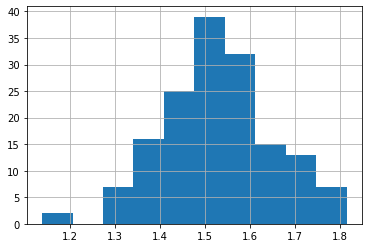

In [13]:
df3["resale"].hist()

# Outlier : Identification and treatments

In [15]:
numerical_variables = df3.select_dtypes(include=['number']).columns

# BOXPLOT Method

In [16]:
numerical_variables

Index(['# ID', 'sales', 'resale', 'price', 'engine_s', 'horsepow', 'wheelbas',
       'width', 'length', 'curb_wgt', 'fuel_cap', 'mpg', 'resale_mv',
       'type_en', 'manufact_en'],
      dtype='object')

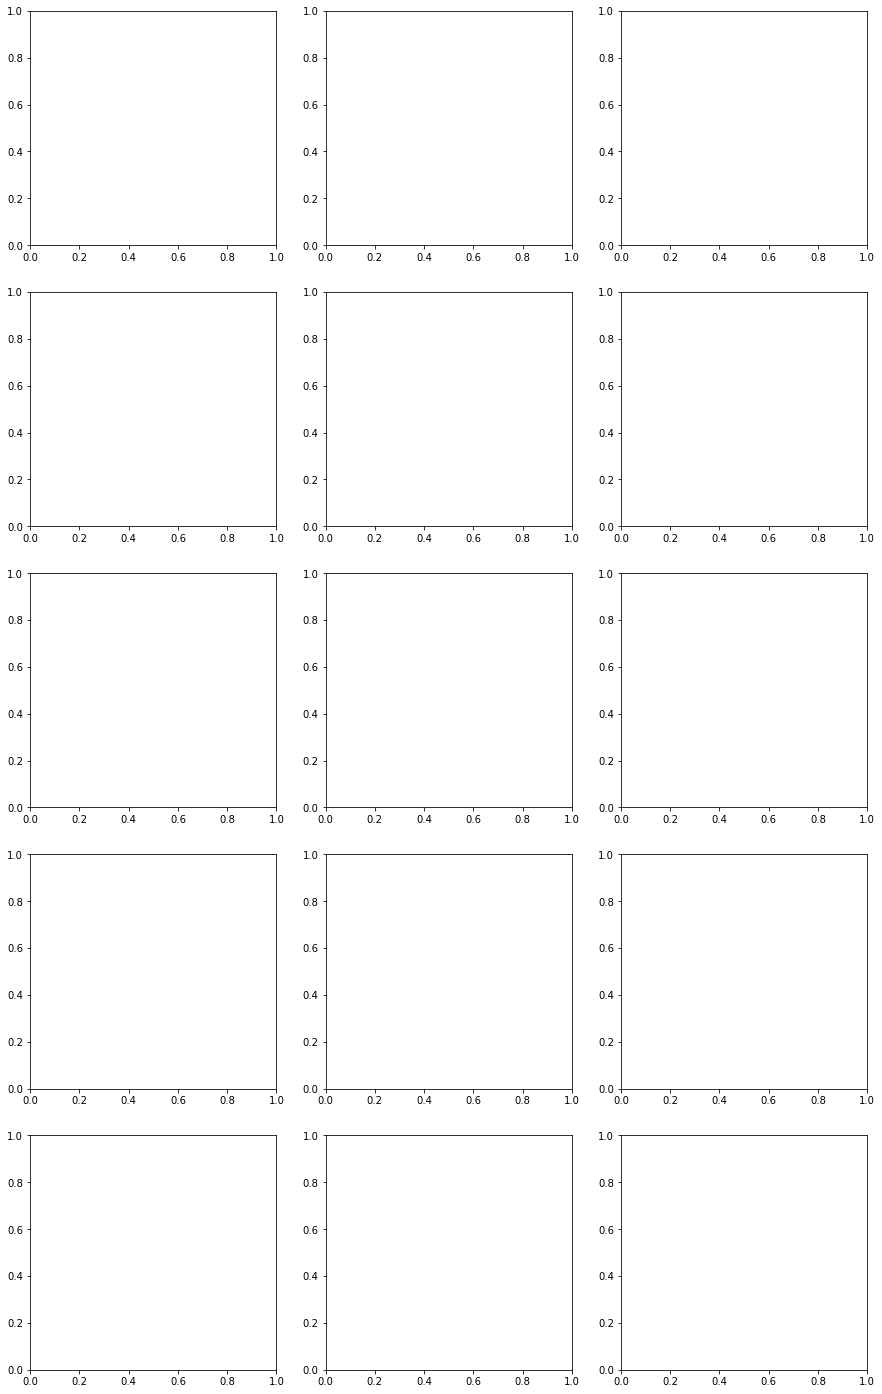

In [19]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
import plotly.express as px
warnings.filterwarnings("ignore")
fig, axes = plt.subplots(nrows=5, ncols=3, figsize=(15,25))
axes_flat=axes.flatten()

    

In [26]:
for ax, col in zip(axes_flat,numerical_variables):
    df3[col].plot(kind='box', ax=ax)
    ax.set_title(col)

# Hide any unused ubplots
for ax in axes_flat[len(numerical_varibles):]:
    ax:axis('off')

ValueError: The number of FixedLocator locations (5), usually from a call to set_ticks, does not match the number of ticklabels (1).

# QQ Plot: Quantile Quantile Plot

In [27]:
import statsmodels.api as sm

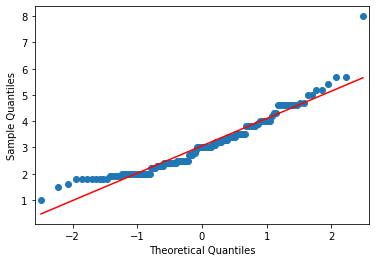

In [31]:
sm.qqplot(df3['engine_s'],line='s')
plt.show()

# Stastical Detection

In [32]:
df3.describe()

,# ID,sales,resale,price,engine_s,horsepow,wheelbas,width,length,curb_wgt,fuel_cap,mpg,resale_mv,type_en,manufact_en
count,156.000000,156.000000,156.000000,156.000000,156.000000,156.000000,156.000000,156.000000,156.000000,156.000000,156.000000,156.000000,156.000000,156.000000,156.000000
mean,79.288462,52.994987,1.528971,27.361321,3.060897,185.948718,107.487179,71.150000,187.343590,3.378026,17.951923,23.846154,18.740823,0.256410,27.361321
std,45.468175,68.248508,0.124041,14.310006,1.044653,56.700321,7.641303,3.451872,13.431754,0.628464,3.887921,4.255022,11.418239,0.438057,10.803669
min,1.000000,0.110000,1.137625,9.235000,1.000000,55.000000,92.600000,62.600000,149.400000,1.895000,10.300000,15.000000,5.160000,0.000000,12.165667
25%,40.750000,14.035000,1.453866,18.081250,2.300000,149.500000,103.000000,68.400000,177.575000,2.973000,15.800000,21.000000,11.959583,0.000000,21.047273
50%,79.500000,29.213000,1.522839,22.799000,3.000000,177.500000,107.000000,70.550000,187.900000,3.355000,17.200000,24.000000,15.182500,0.000000,22.949167
75%,118.250000,68.069750,1.596527,31.938750,3.575000,215.000000,112.200000,73.425000,196.125000,3.788750,19.575000,26.000000,20.272917,1.000000,29.045833
max,157.000000,540.561000,1.814089,85.500000,8.000000,450.000000,138.700000,79.900000,224.500000,5.572000,32.000000,45.000000,67.550000,1.000000,62.473333


# Inter Quartile Range Method

In [ ]:
# Lets define a function to define various quartiles, which help us figure out outliers

In [37]:
def Outlier_caps(df,var_nm):
    Q1= np.percentile(df3[var_nm],25)
    Q3= np.percentile(df3[var_nm],75)
    IQR = Q3-Q1
    upper = Q3 + 1.5*IQR
    lower = Q1 - 1.5*IQR
    Q5 = np.percentile(df3[var_nm],5)
    Q95 = np.percentile(df3[var_nm],95)
    d = {'25 percentile':Q1,'75 percentile':Q3,'IQR':IQR,'UB': upper,'LB': lower,'5 Percentile':Q5,'95 Percentile':Q95}
    final = pd.Series(d)
    return final

In [38]:
var =  Outlier_caps(df3,'sales')

In [39]:
var

25 percentile     14.035000
75 percentile     68.069750
IQR               54.034750
UB               149.121875
LB               -67.017125
5 Percentile       1.870500
95 Percentile    186.233000
dtype: float64

In [40]:
df3['sales'].sort_values(ascending = False)

55     540.561
51     276.747
136    247.994
48     245.815
57     230.902
        ...   
124      1.280
107      1.112
98       0.954
38       0.916
82       0.110
Name: sales, Length: 156, dtype: float64

In [41]:
df3.iloc[55]

# ID                       57
manufact                 Ford
sales                 540.561
resale                 1.5209
type                    Truck
price                  26.935
engine_s                  4.6
horsepow                220.0
wheelbas                138.5
width                    79.1
length                  224.5
curb_wgt                4.241
fuel_cap                 25.1
mpg                      18.0
resale_mv              15.075
type_en                     1
manufact_wt_rare         Ford
manufact_en         21.047273
Name: 55, dtype: object

In [ ]:
#this is an outlier, lets treat outliers with capping and flooring

In [46]:
df3['sales_outlier'] = np.where(df3['sales']>var['95 Percentile'],var['95 Percentile'],
                                np.where(df3['sales']<var['5 Percentile'],var['5 Percentile'],df3['sales']))

In [ ]:
# df3.iloc[55] # sales_oulier is 95 Percentile value

# CLIP Method

In [50]:
df3['sales_outlier_clip']=df3['sales'].clip(lower = var['5 Percentile'],upper=var['95 Percentile'])

In [52]:
df3.iloc[55]

# ID                         57
manufact                   Ford
sales                   540.561
resale                   1.5209
type                      Truck
price                    26.935
engine_s                    4.6
horsepow                  220.0
wheelbas                  138.5
width                      79.1
length                    224.5
curb_wgt                  4.241
fuel_cap                   25.1
mpg                        18.0
resale_mv                15.075
type_en                       1
manufact_wt_rare           Ford
manufact_en           21.047273
sales_outlier           186.233
sales_outlier_clip      186.233
Name: 55, dtype: object

# Build a generalise function for capping and flooring

In [61]:
def cap_outlier(df,col_name,lower_percentile,upper_percentile):
    
    
    #calc Lower and Upper quantile
    lower_bound = df[col_name].quantile(lower_percentile)
    upper_bound = df[col_name].quantile(upper_percentile)
    
    #for CAP and FLOORING logic
    
    df[col_name + "_treated"] = df3[col_name].clip( lower = lower_bound , upper = upper_bound )
    
    return df[col_name + "_treated"]



In [62]:
cap_outlier(df3,'sales',0.01,0.99)

0      16.919
1      39.384
2      14.114
3       8.588
4      20.397
        ...  
151     3.545
152    15.245
153    17.531
154     3.493
155    18.969
Name: sales_treated, Length: 156, dtype: float64